# Revista Anfibia database: corpus-oriented exploration

This notebook explains what is contained in `revistaanfibia_prod_database_2026-06-17.sql`
and turns the editorial portion of the WordPress dump into a candidate document corpus.

**Main finding to keep in mind:** this is a complete MariaDB/WordPress production dump,
not a ready-made text corpus. Most tables support plugins, caching, security, newsletters,
redirects, and site administration. Editorial text primarily lives in `wp_posts`; labels
such as categories and tags live in the three taxonomy tables.

The workflow streams through the SQL file, so it does not read the 451 MB dump into memory
or require a running MariaDB server. Runtime depends on disk speed and is usually a few minutes.

## 1. Setup and provenance

The dump header identifies MariaDB 10.11 and database `revistaanfibia_prod`. The export date
is encoded in the filename. Keep the original dump immutable: it contains operational and
personal data in addition to public editorial material.

In [ ]:
from collections import Counter
from pathlib import Path
import html
import re

import matplotlib.pyplot as plt
import pandas as pd
from bs4 import BeautifulSoup
from IPython.display import display

pd.set_option("display.max_colwidth", 90)

# Rutas estándar del proyecto
BASE_DIR = Path.cwd().resolve()
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

RAW_DATA_PATH = BASE_DIR / "data" / "raw"
PROCESSED_DATA_PATH = BASE_DIR / "data" / "processed"

DUMP_PATH = RAW_DATA_PATH / "revistaanfibia_prod_database_2026-06-17.sql"
assert DUMP_PATH.exists(), f"Falta el archivo SQL en: {DUMP_PATH.resolve()}"

dump_mb = DUMP_PATH.stat().st_size / 1024**2
print(f"Dump: {DUMP_PATH.name}")
print(f"Size: {dump_mb:,.1f} MiB")

Dump: revistaanfibia_prod_database_2026-06-17.sql
Size: 430.7 MiB


## 2. Streaming SQL helpers

MariaDB string escaping is not CSV escaping, and values can contain commas, quotes, and
parentheses. The small state machines below respect quoted strings and backslash escapes.
They are intentionally limited to the regular `INSERT INTO ... VALUES` format used by this dump.

In [2]:
CREATE_RE = re.compile(r"^CREATE TABLE `([^`]+)` \(")
COLUMN_RE = re.compile(r"^\s+`([^`]+)`\s+(.+?)(?:,)?$")
INSERT_RE = re.compile(r"^INSERT INTO `([^`]+)` VALUES\s*(.*)$")

def iter_insert_payloads(path, wanted=None):
    """Yield (table, VALUES payload) without loading the dump into memory."""
    table, parts = None, []
    with path.open(encoding="utf-8", errors="replace") as handle:
        for line in handle:
            if table is None:
                match = INSERT_RE.match(line)
                if not match:
                    continue
                candidate, first = match.groups()
                if wanted is not None and candidate not in wanted:
                    # Still consume the statement, but do not retain its text.
                    table = False
                else:
                    table = candidate
                    parts = [first]
            elif table is not False:
                parts.append(line)

            if table is not None and line.rstrip().endswith(";"):
                if table is not False:
                    payload = "".join(parts).rstrip()
                    yield table, payload[:-1] if payload.endswith(";") else payload
                table, parts = None, []

def count_tuples(payload):
    count = depth = 0
    quoted = escaped = False
    for char in payload:
        if escaped:
            escaped = False
        elif char == "\\" and quoted:
            escaped = True
        elif char == "'":
            quoted = not quoted
        elif not quoted:
            if char == "(":
                if depth == 0:
                    count += 1
                depth += 1
            elif char == ")":
                depth -= 1
    return count

MYSQL_ESCAPES = {"0": "\0", "b": "\b", "n": "\n", "r": "\r", "t": "\t", "Z": "\x1a"}

def parse_values(payload):
    """Parse one MariaDB VALUES payload into Python rows."""
    rows, row, token = [], [], []
    quoted = escaped = field_was_quoted = False
    depth = 0

    def finish_field():
        nonlocal field_was_quoted
        raw = "".join(token)
        row.append(None if not field_was_quoted and raw.upper() == "NULL" else raw)
        token.clear()
        field_was_quoted = False

    for char in payload:
        if escaped:
            token.append(MYSQL_ESCAPES.get(char, char))
            escaped = False
        elif quoted and char == "\\":
            escaped = True
        elif char == "'":
            quoted = not quoted
            field_was_quoted = True
        elif not quoted and char == "(" and depth == 0:
            depth = 1
            row, token = [], []
        elif not quoted and depth == 1 and char == ",":
            finish_field()
        elif not quoted and char == ")" and depth == 1:
            finish_field()
            rows.append(row)
            depth = 0
        elif depth:
            token.append(char)
    return rows

def extract_schemas(path):
    schemas, current = {}, None
    with path.open(encoding="utf-8", errors="replace") as handle:
        for line in handle:
            match = CREATE_RE.match(line)
            if match:
                current = match.group(1)
                schemas[current] = []
            elif current and line.startswith(") ENGINE="):
                current = None
            elif current:
                match = COLUMN_RE.match(line)
                if match:
                    schemas[current].append(match.group(1))
    return schemas

## 3. What tables are present?

The inventory counts SQL tuples rather than querying a restored database. The grouping is a
readable interpretation of familiar WordPress/plugin prefixes, not metadata stored in the dump.
Tables may legitimately have zero exported rows.

In [3]:
schemas = extract_schemas(DUMP_PATH)
row_counts = Counter()
for table, payload in iter_insert_payloads(DUMP_PATH):
    row_counts[table] += count_tuples(payload)

def table_family(name):
    if name in {"wp_posts", "wp_postmeta", "wp_comments", "wp_commentmeta"}:
        return "content"
    if name in {"wp_terms", "wp_termmeta", "wp_term_taxonomy", "wp_term_relationships"}:
        return "taxonomy"
    if name in {"wp_users", "wp_usermeta"}:
        return "users / personal data"
    prefixes = {
        "wp_actionscheduler_": "scheduled jobs", "wp_sendpress_": "newsletter",
        "wp_wf": "Wordfence security", "wp_yoast_": "SEO",
        "wp_redirection_": "redirects", "wp_wpr_": "performance/cache",
        "wp_ewwwio_": "image optimization",
    }
    return next((label for prefix, label in prefixes.items() if name.startswith(prefix)), "site/plugin support")

inventory = pd.DataFrame([
    {"table": table, "family": table_family(table), "columns": len(columns),
     "rows_in_dump": row_counts.get(table, 0)}
    for table, columns in schemas.items()
]).sort_values("rows_in_dump", ascending=False, ignore_index=True)

print(f"{len(inventory)} tables; {inventory.rows_in_dump.sum():,} exported rows in total")
display(inventory.groupby("family", as_index=False).agg(tables=("table", "count"), rows=("rows_in_dump", "sum")).sort_values("rows", ascending=False))
display(inventory.head(20))

87 tables; 1,921,731 exported rows in total


,family,tables,rows
2,content,4,526487
10,users / personal data,2,327154
4,newsletter,14,306666
7,scheduled jobs,4,280303
3,image optimization,3,206204
9,taxonomy,4,89342
1,Wordfence security,25,58652
0,SEO,6,55652
5,performance/cache,7,28207
8,site/plugin support,14,22540


,table,family,columns,rows_in_dump
0,wp_postmeta,content,4,407438
1,wp_usermeta,users / personal data,4,310764
2,wp_actionscheduler_claims,scheduled jobs,2,280286
3,wp_ewwwio_images,image optimization,19,206204
4,wp_sendpress_subscribers_event,newsletter,10,176427
5,wp_posts,content,23,118901
6,wp_term_relationships,taxonomy,3,87078
7,wp_sendpress_subscribers,newsletter,13,63435
8,wp_sendpress_subscribers_tracker,newsletter,7,43067
9,wp_yoast_seo_links,SEO,12,38899


In [4]:
core_names = ["wp_posts", "wp_postmeta", "wp_terms", "wp_term_taxonomy",
              "wp_term_relationships", "wp_users", "wp_comments"]
display(inventory[inventory.table.isin(core_names)])
print("wp_posts columns:")
print(", ".join(schemas["wp_posts"]))

,table,family,columns,rows_in_dump
0,wp_postmeta,content,4,407438
5,wp_posts,content,23,118901
6,wp_term_relationships,taxonomy,3,87078
13,wp_users,users / personal data,10,16390
30,wp_term_taxonomy,taxonomy,6,1106
31,wp_terms,taxonomy,5,1106
38,wp_comments,content,15,148


wp_posts columns:
ID, post_author, post_date, post_date_gmt, post_content, post_title, post_excerpt, post_status, comment_status, ping_status, post_password, post_name, to_ping, pinged, post_modified, post_modified_gmt, post_content_filtered, post_parent, guid, menu_order, post_type, post_mime_type, comment_count


### Reading the WordPress model

- `wp_posts` is polymorphic: articles, pages, author profiles, media attachments, revisions,
  podcasts, and other custom post types share one table. `post_type` and `post_status` are essential filters.
- `wp_postmeta` is a large key/value extension table. It may hold editorial fields, but also
  page-builder and plugin state. It should be audited by `meta_key` before selective use.
- `wp_terms` stores names; `wp_term_taxonomy` says whether each term is a category, tag, or
  custom taxonomy; `wp_term_relationships` links them to a post ID.
- `wp_users`, newsletter, comments, logs, IP/security, and configuration tables can contain
  personal or sensitive data. They are unnecessary for text topic modeling and are not loaded here.

## 4. Load only the corpus-relevant tables

This is a second streaming pass over the dump. Numeric IDs are converted after parsing.

In [5]:
wanted = {"wp_posts", "wp_terms", "wp_term_taxonomy", "wp_term_relationships"}
collected = {table: [] for table in wanted}
for table, payload in iter_insert_payloads(DUMP_PATH, wanted):
    collected[table].extend(parse_values(payload))

frames = {}
for table, rows in collected.items():
    frames[table] = pd.DataFrame(rows, columns=schemas[table])
    print(f"{table}: {len(frames[table]):,} rows")

posts = frames["wp_posts"].copy()
for column in ["ID", "post_author", "post_parent", "comment_count"]:
    posts[column] = pd.to_numeric(posts[column], errors="coerce").astype("Int64")
posts["post_date"] = pd.to_datetime(posts["post_date"], errors="coerce")

wp_posts: 118,901 rows
wp_term_taxonomy: 1,106 rows
wp_terms: 1,106 rows
wp_term_relationships: 87,078 rows


## 5. Which rows look like documents?

Counts by type and status expose the difference between public editorial objects and WordPress
history/administration. A revision is not a separate document; an attachment is media metadata;
drafts and private rows were never necessarily public.

In [6]:
type_status = (posts.groupby(["post_type", "post_status"], dropna=False)
               .size().rename("rows").reset_index()
               .sort_values("rows", ascending=False))
display(type_status.head(35))

published = posts[posts.post_status.eq("publish")].copy()
published_type_counts = published.post_type.value_counts()
display(published_type_counts.rename_axis("post_type").to_frame("published_rows"))

,post_type,post_status,rows
35,spnl_log,publish,71546
2,attachment,inherit,27662
33,sp_settings,draft,10455
27,post,publish,3622
6,autor,publish,2288
30,revision,inherit,1608
43,workshops,publish,318
3,attachment,private,294
50,wprss_feed_item,publish,261
28,postman_sent_mail,private,250


,published_rows
post_type,
spnl_log,71546
post,3622
autor,2288
workshops,318
wprss_feed_item,261
web-story,80
page,77
oembed_cache,59
sp_report,33


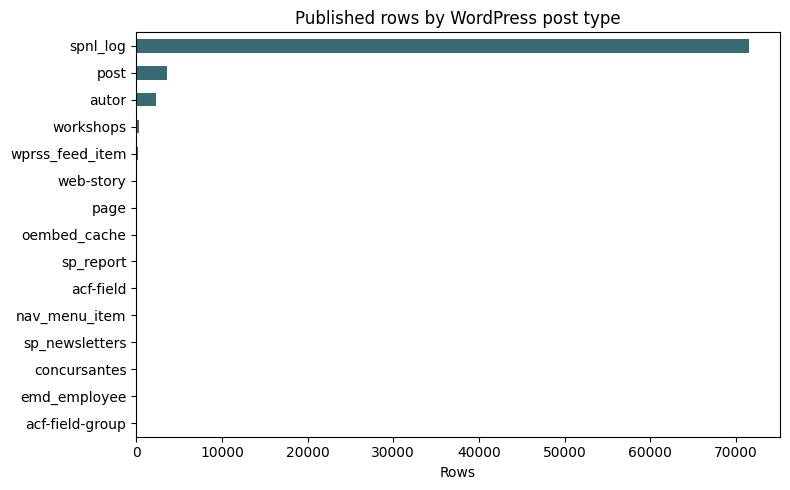

In [7]:
ax = published_type_counts.head(15).sort_values().plot.barh(figsize=(8, 5), color="#376a73")
ax.set(title="Published rows by WordPress post type", xlabel="Rows", ylabel="")
plt.tight_layout()
plt.show()

## 6. Convert stored HTML into analysis text

Topic models should not learn HTML tags, Gutenberg block comments, shortcodes, non-breaking
spaces, or repeated navigation markup. This conservative cleaner preserves visible text and
paragraph boundaries. Inspect samples before adding stronger language-specific normalization.

In [8]:
SHORTCODE_RE = re.compile(r"\[(?:/?)[A-Za-z][^\]]*\]")

def clean_wordpress_text(value):
    value = value or ""
    if not any(marker in value for marker in ("<", "&", "[")):
        return re.sub(r"\s+", " ", value).strip()
    soup = BeautifulSoup(value, "html.parser")
    for element in soup(["script", "style", "noscript"]):
        element.decompose()
    text = soup.get_text(" ")
    text = SHORTCODE_RE.sub(" ", html.unescape(text))
    return re.sub(r"\s+", " ", text).strip()

published["title_text"] = published.post_title.map(clean_wordpress_text)
published["body_text"] = published.post_content.map(clean_wordpress_text)
published["excerpt_text"] = published.post_excerpt.map(clean_wordpress_text)
published["document_text"] = (published.title_text + ". " + published.body_text).str.strip(" .")
published["word_count"] = published.document_text.str.findall(r"(?u)\b\w+\b").str.len()

length_summary = (published.groupby("post_type").word_count
                  .agg(["count", "median", "mean", "max"])
                  .sort_values("count", ascending=False))
display(length_summary.round(1).head(20))

,count,median,mean,max
post_type,,,,
spnl_log,71546,14.0,12.4,330
post,3622,2275.5,2509.1,19687
autor,2288,121.0,138.3,699
workshops,318,500.5,575.9,4746
wprss_feed_item,261,5.0,94.9,1128
web-story,80,434.0,453.5,828
page,77,42.0,238.7,2116
oembed_cache,59,1.0,1.8,21
sp_report,33,311.0,303.8,622


In [9]:
sample_columns = ["ID", "post_type", "post_date", "title_text", "word_count"]
display(published.loc[published.word_count.ge(100), sample_columns].sample(
    min(10, published.word_count.ge(100).sum()), random_state=42
).sort_values("post_date"))

,ID,post_type,post_date,title_text,word_count
1193,2143,post,2013-08-25 16:15:06,Imaginate este lugar todo lleno de armas,4071
73,258,post,2014-04-22 15:14:40,UN AMOR ETERNO DE SEIS DÍAS,5114
33092,36239,post,2015-12-29 15:04:29,Red internacional de periodismo narrativo,459
41115,44689,post,2016-06-04 12:28:21,Un movimiento sin dueñas,2508
49278,53411,post,2016-11-16 11:13:55,Periodismo mutante,1872
57369,62453,post,2017-03-22 08:24:12,Caer en la pública,3086
109076,185054,post,2023-04-25 12:00:00,Etiquetado frontal para lxs bebés del futuro,2633
109563,186835,autor,2023-06-21 09:24:15,Guillermina Espósito,104
110016,188492,post,2023-08-04 12:22:18,San Benito no es Bad Bunny,3413
113287,199160,post,2024-10-03 00:04:45,El lugar donde se proyectan los sueños,4524


## 7. Attach categories, tags, and custom taxonomies

Terms are retained as lists rather than flattened strings. This supports validation, stratified
analysis, and later comparison between discovered topics and editorial labels.

In [10]:
terms = frames["wp_terms"][["term_id", "name", "slug"]].copy()
tax = frames["wp_term_taxonomy"][["term_taxonomy_id", "term_id", "taxonomy"]].copy()
rel = frames["wp_term_relationships"][["object_id", "term_taxonomy_id"]].copy()
for frame, columns in [(terms, ["term_id"]), (tax, ["term_taxonomy_id", "term_id"]),
                       (rel, ["object_id", "term_taxonomy_id"])]:
    for column in columns:
        frame[column] = pd.to_numeric(frame[column], errors="coerce").astype("Int64")

post_terms = (rel.merge(tax, on="term_taxonomy_id", how="left")
                .merge(terms, on="term_id", how="left"))
taxonomy_counts = post_terms.taxonomy.value_counts()
display(taxonomy_counts.rename_axis("taxonomy").to_frame("relationships"))

term_lists = (post_terms.dropna(subset=["taxonomy", "name"])
              .groupby(["object_id", "taxonomy"])["name"]
              .agg(lambda values: sorted(set(values)))
              .unstack(fill_value=[]))
published = published.merge(term_lists, left_on="ID", right_index=True, how="left")
for column in term_lists.columns:
    published[column] = published[column].map(lambda value: value if isinstance(value, list) else [])

,relationships
taxonomy,
spnl_log_type,71546
post_tag,4440
category,3929
text_type,2650
web_story_media_source,2001
etiquetas-de-recomendados,724
destacado-medio,699
recomendado,416
destacado-arriba,409


## 8. Define a first topic-model corpus

The rule below is deliberately explicit. It keeps published, substantial text from likely
editorial post types and excludes author bios, landing pages, attachments, revisions, and
plugin objects. Review the observed type table above and edit `INCLUDED_POST_TYPES` if the
newsroom's meaning of a document differs.

A 150-word floor removes placeholders and link-only entries without pretending that it is a
universal modeling threshold. The raw ID, date, title, URL, type, and taxonomies remain attached
so model results can be audited against source records.

In [11]:
# `post` is the main long-form publication type. `especial` also contains editorial text.
# Consider `web-story` separately: it is shorter and its text may depend on slide structure.
INCLUDED_POST_TYPES = {"post", "especial"}
MIN_WORDS = 150

corpus = published[
    published.post_type.isin(INCLUDED_POST_TYPES)
    & published.word_count.ge(MIN_WORDS)
    & published.body_text.ne("")
].copy()

taxonomy_columns = [c for c in post_terms.taxonomy.dropna().unique() if c in corpus.columns]
corpus_columns = ["ID", "post_date", "post_type", "title_text", "body_text",
                  "document_text", "word_count", "guid"] + sorted(taxonomy_columns)
corpus = corpus[corpus_columns].sort_values(["post_date", "ID"]).reset_index(drop=True)

print(f"Candidate corpus: {len(corpus):,} documents")
print(f"Date range: {corpus.post_date.min():%Y-%m-%d} to {corpus.post_date.max():%Y-%m-%d}")
display(corpus.groupby("post_type").word_count.agg(["count", "median", "mean", "max"]).round(1))
display(corpus[["ID", "post_date", "post_type", "title_text", "word_count"]].head(10))

Candidate corpus: 3,566 documents
Date range: 2012-05-14 to 2026-06-16


,count,median,mean,max
post_type,,,,
especial,8,318.5,338.6,644
post,3558,2302.0,2553.1,19687


,ID,post_date,post_type,title_text,word_count
0,15668,2012-05-14 13:43:22,post,La China invisible,4838
1,15706,2012-05-24 13:36:12,post,El rico que se cree Steve Jobs,3170
2,15743,2012-06-05 14:52:58,post,La vaca sagrada,4907
3,15695,2012-06-14 10:16:11,post,Los arruinados del Paraná,4056
4,15687,2012-06-25 14:52:05,post,De Chile a Tacna: una historia de carniceros y cirujanos,1976
5,14466,2012-06-28 14:19:51,post,Bolivia en llamas,3173
6,14454,2012-07-06 13:27:04,post,Los líderes de la primavera mexicana (I),5063
7,3650,2012-07-16 17:08:34,post,Nunca te metas con las mariscadoras de Vigo,2466
8,3669,2012-07-23 17:32:48,post,"Lucía, la remadora olímpica de las manos imposibles",1353
9,3639,2012-07-30 15:38:38,post,El fisicoculturista que no puede mirarse en el espejo,3447


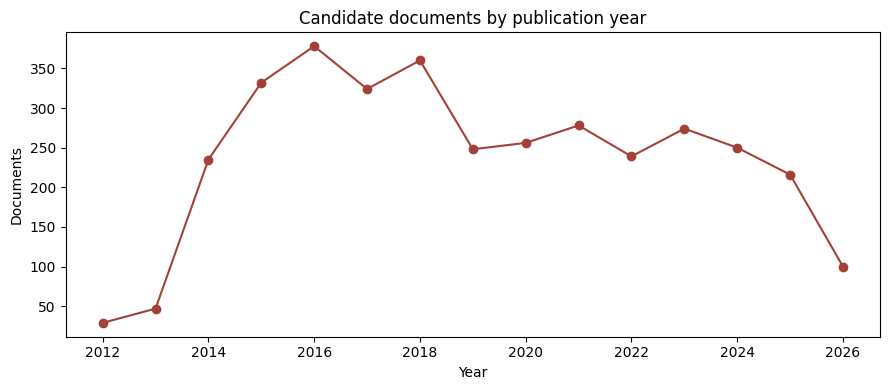

In [12]:
yearly = corpus.assign(year=corpus.post_date.dt.year).groupby("year").size()
ax = yearly.plot(figsize=(9, 4), marker="o", color="#a34138")
ax.set(title="Candidate documents by publication year", xlabel="Year", ylabel="Documents")
plt.tight_layout()
plt.show()

## 9. Quality checks before modeling

These checks flag common corpus problems: duplicate content, duplicate IDs, implausible dates,
very short documents, and empty titles. Exact duplicate text can arise from migrations or
republishing, so inspect rather than blindly delete it.

In [13]:
checks = pd.Series({
    "duplicate IDs": int(corpus.ID.duplicated().sum()),
    "exact duplicate document_text rows": int(corpus.document_text.duplicated().sum()),
    "empty titles": int(corpus.title_text.eq("").sum()),
    "missing dates": int(corpus.post_date.isna().sum()),
    "dates after dump date (2026-06-17)": int((corpus.post_date > pd.Timestamp("2026-06-17")).sum()),
    f"documents below {MIN_WORDS} words": int(corpus.word_count.lt(MIN_WORDS).sum()),
}, name="count")
display(checks.to_frame())

duplicates = corpus[corpus.document_text.duplicated(keep=False)].sort_values("document_text")
display(duplicates[["ID", "post_date", "post_type", "title_text", "word_count"]].head(20))

,count
duplicate IDs,0
exact duplicate document_text rows,1
empty titles,0
missing dates,0
dates after dump date (2026-06-17),0
documents below 150 words,0


,ID,post_date,post_type,title_text,word_count
700,40375,2016-03-14 10:34:40,post,"Escrituras del yo, de lo personal a lo colectivo",664
855,46921,2016-07-22 11:00:37,post,"Escrituras del yo, de lo personal a lo colectivo",664


## 10. Optional export and modeling handoff

Uncomment an export only after reviewing the corpus definition and quality checks. Parquet
preserves list-valued taxonomy columns and datetimes better than CSV (requires `pyarrow`).

Recommended next decisions before fitting a topic model:

1. Confirm which custom post types are genuinely editorial documents.
2. Inspect frequent `wp_postmeta.meta_key` values for important fields such as bylines or dek/volanta.
3. Detect language; separate or explicitly model non-Spanish documents.
4. Deduplicate migrated/republished text and decide how to treat podcasts and transcripts.
5. Normalize Spanish text conservatively, preserving names and multiword expressions; compare
   a count/TF-IDF baseline with the selected topic model and validate topics with dates and categories.

**Privacy boundary:** export only the editorial corpus. Do not carry user email, subscriber,
comment-author, IP/security, or configuration fields into analysis artifacts.

In [ ]:
# # Exportar el corpus a la carpeta de datos procesados
# output_parquet = PROCESSED_DATA_PATH / "revistaanfibia_topic_corpus.parquet"
# output_csv = PROCESSED_DATA_PATH / "revistaanfibia_topic_corpus.csv"

# corpus.to_parquet(output_parquet, index=False)
# corpus.drop(columns=taxonomy_columns).to_csv(output_csv, index=False, encoding="utf-8")

# print(f"Corpus Parquet exportado a: {output_parquet}")
# print(f"Corpus CSV exportado a: {output_csv}")